In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("day.csv")


In [9]:
df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [10]:
df.shape

(731, 16)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [14]:
df["cnt"].describe()

count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

In [15]:
df["dteday"] = pd.to_datetime(df["dteday"])

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

In [17]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [18]:
for column in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(column, ":", sorted(df[column].unique()))

season : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr : [np.int64(0), np.int64(1)]
mnth : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday : [np.int64(0), np.int64(1)]
weekday : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday : [np.int64(0), np.int64(1)]
weathersit : [np.int64(1), np.int64(2), np.int64(3)]


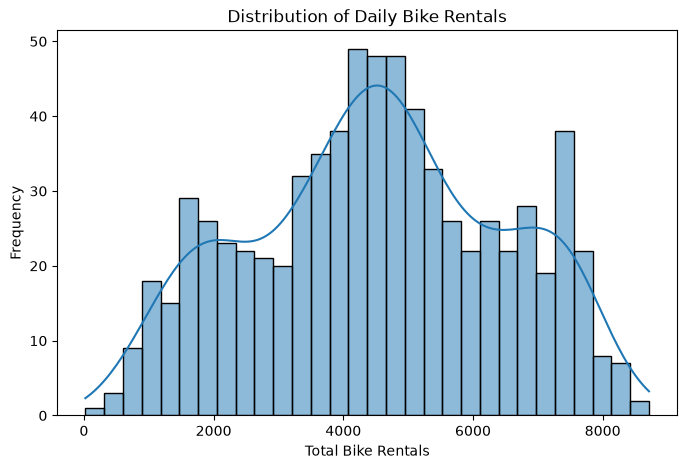

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df["cnt"], bins=30, kde=True)
plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.show()

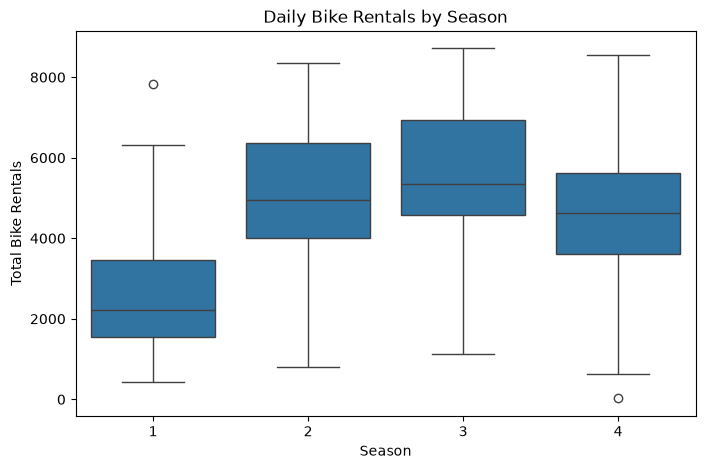

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="season", y="cnt", data=df)
plt.title("Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Total Bike Rentals")
plt.show()

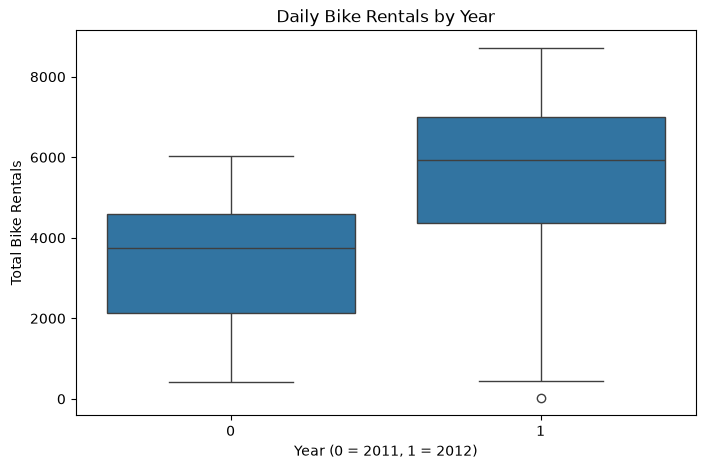

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="yr", y="cnt", data=df)
plt.title("Daily Bike Rentals by Year")
plt.xlabel("Year (0 = 2011, 1 = 2012)")
plt.ylabel("Total Bike Rentals")
plt.show()

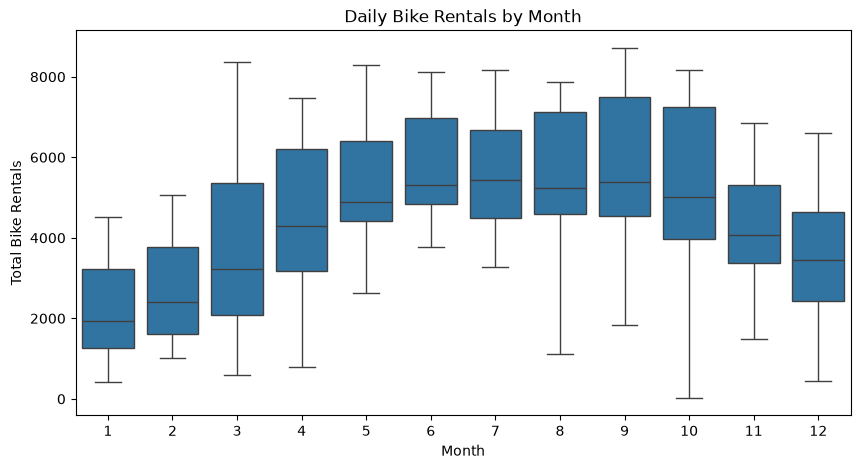

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="mnth", y="cnt", data=df)
plt.title("Daily Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Total Bike Rentals")
plt.show()

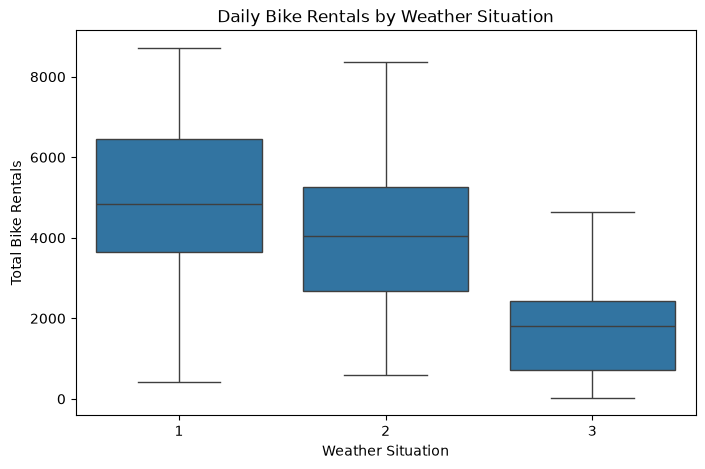

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="weathersit", y="cnt", data=df)
plt.title("Daily Bike Rentals by Weather Situation")
plt.xlabel("Weather Situation")
plt.ylabel("Total Bike Rentals")
plt.show()

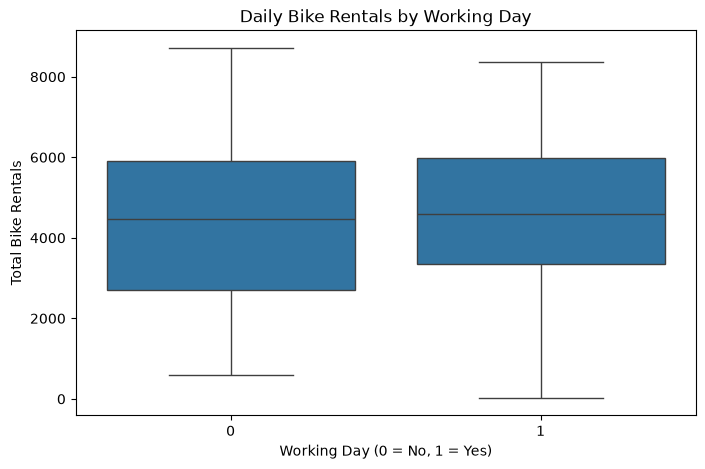

In [24]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="workingday", y="cnt", data=df)
plt.title("Daily Bike Rentals by Working Day")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Total Bike Rentals")
plt.show()

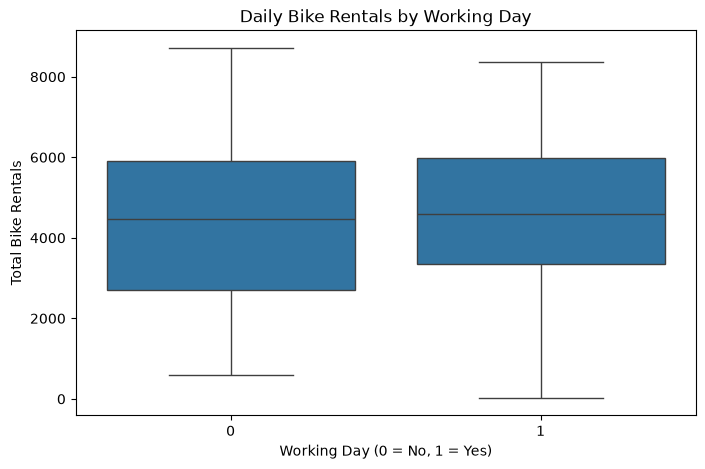

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="workingday", y="cnt", data=df)
plt.title("Daily Bike Rentals by Working Day")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Total Bike Rentals")
plt.show()

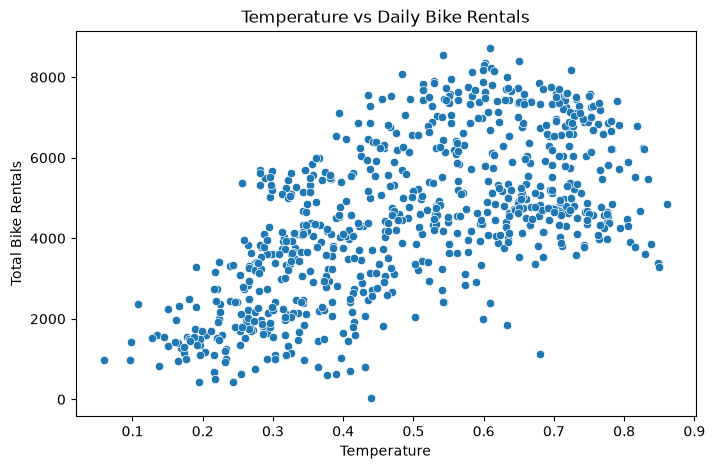

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="temp", y="cnt", data=df)
plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Total Bike Rentals")
plt.show()

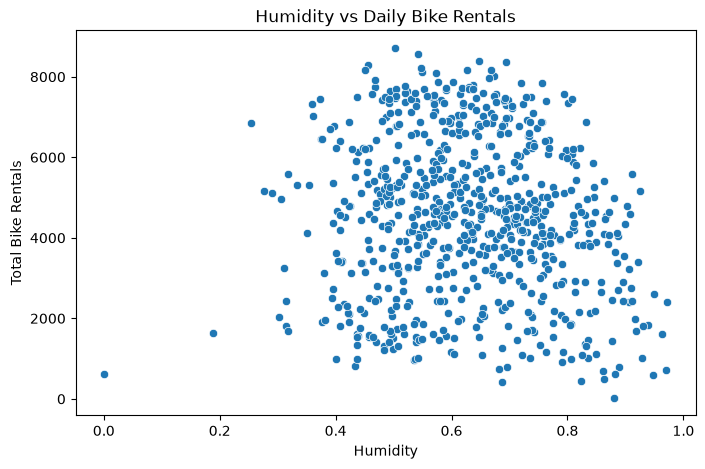

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="hum", y="cnt", data=df)
plt.title("Humidity vs Daily Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Total Bike Rentals")
plt.show()

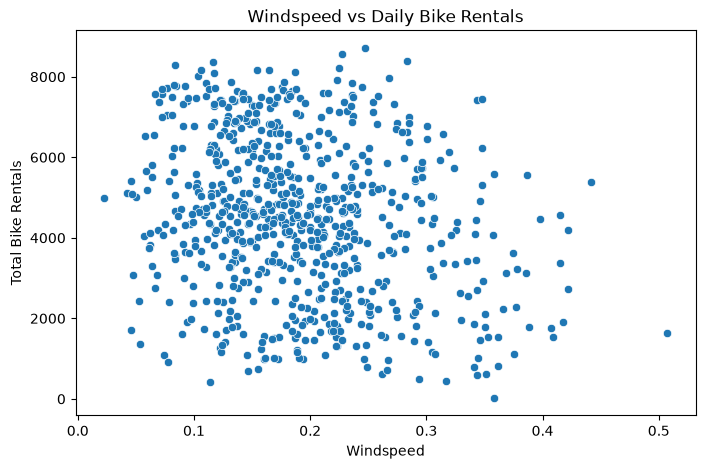

In [28]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="windspeed", y="cnt", data=df)
plt.title("Windspeed vs Daily Bike Rentals")
plt.xlabel("Windspeed")
plt.ylabel("Total Bike Rentals")
plt.show()

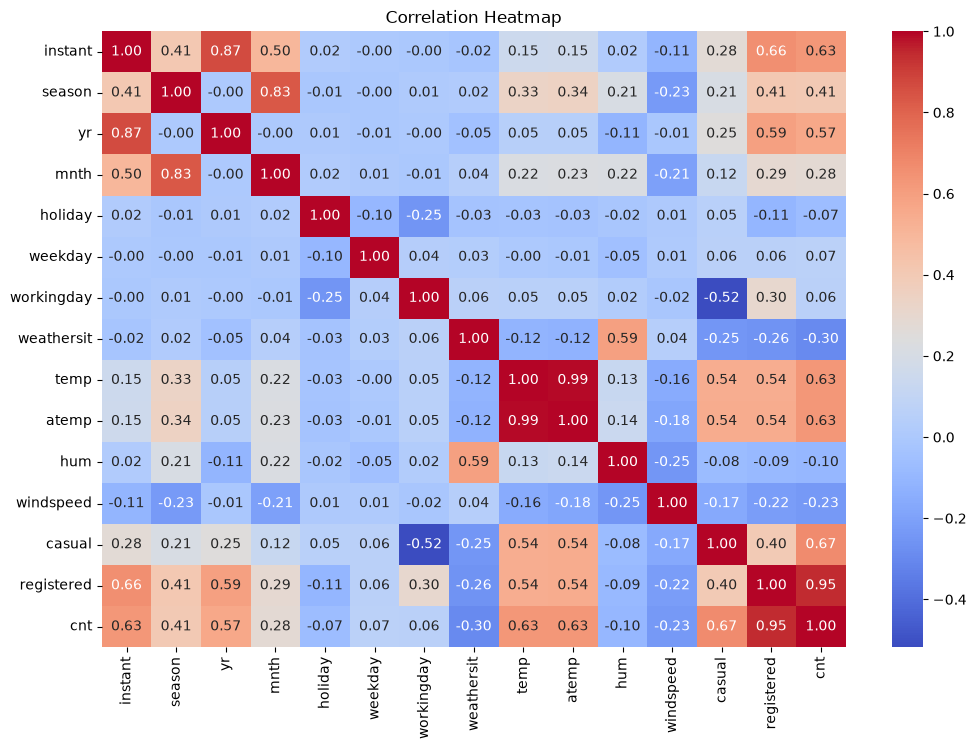

In [29]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [30]:
X = df[[
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]]

y = df["cnt"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (731, 11)
Target shape: (731,)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (584, 11)
Testing data: (147, 11)


In [32]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression
MAE : 617.3930656443374
RMSE: 831.2851545662685
R²  : 0.8276670090367213


In [34]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Regression model trained successfully.")

Decision Tree Regression model trained successfully.


In [35]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R²  :", r2_dt)

Decision Tree Regression
MAE : 662.8027210884354
RMSE: 983.9813338199676
R²  : 0.7585417237651239


In [36]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regression model trained successfully.")

Random Forest Regression model trained successfully.


In [37]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression
MAE : 429.958299319728
RMSE: 677.0871048743101
R²  : 0.8856707218333267


In [38]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(random_state=42)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Regression model trained successfully.")

Gradient Boosting Regression model trained successfully.


In [39]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Regression")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting Regression
MAE : 462.7689669575953
RMSE: 661.3752266914838
R²  : 0.8909152042376449


In [40]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_gb
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,617.393066,831.285155,0.827667
1,Decision Tree,662.802721,983.981334,0.758542
2,Random Forest,429.958299,677.087105,0.885671
3,Gradient Boosting,462.768967,661.375227,0.890915


In [41]:
best_model = model_comparison.loc[model_comparison["RMSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R²:", best_model["R2"])

Best Model: Gradient Boosting
MAE: 462.7689669575953
RMSE: 661.3752266914838
R²: 0.8909152042376449


In [42]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
7,temp,0.351733
1,yr,0.279657
8,atemp,0.155569
9,hum,0.059340
0,season,0.052566
10,windspeed,0.032912
2,mnth,0.026553
6,weathersit,0.018494
4,weekday,0.015780
5,workingday,0.004390


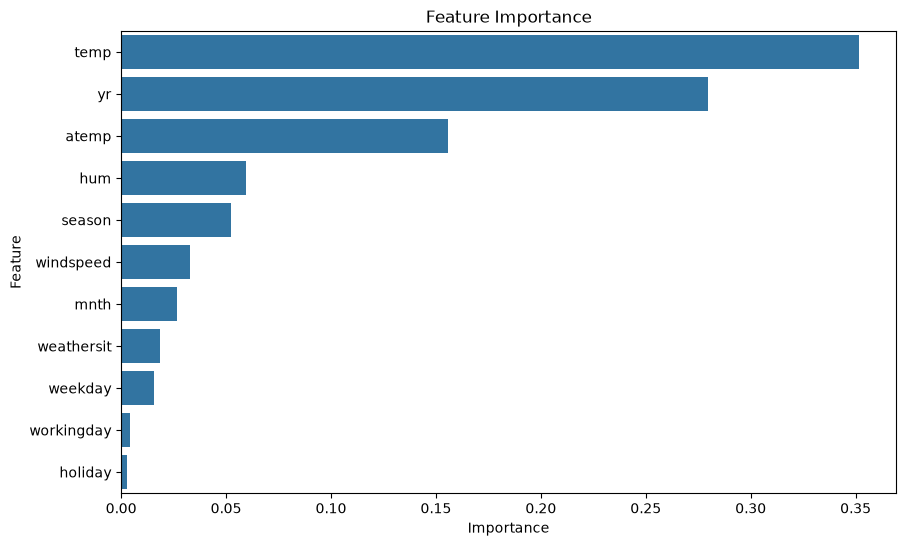

In [43]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [ ]:
## Challenges Faced and Techniques Used

### 1. Data Quality
The dataset was checked for missing values and duplicate records. No missing values or duplicate records were found in the daily dataset.

### 2. Date Handling
The `dteday` column was converted from text format to datetime format to make the date information suitable for analysis.

### 3. Exploratory Data Analysis
Different visualizations were used to understand bike rental patterns based on season, year, month, weather, working days, temperature, humidity, and windspeed.

### 4. Target Leakage
The `casual` and `registered` columns were excluded from the prediction features because they are components of the target variable `cnt`.

### 5. Model Comparison
Multiple regression models were trained and evaluated using MAE, RMSE, and R² to compare their performance.

In [ ]:
## Conclusion

The Bike Rental dataset was analyzed to understand the factors affecting daily bike rental demand.

Exploratory data analysis was performed using different statistical summaries and visualizations. The relationship between bike rentals and factors such as season, year, month, weather, temperature, humidity, windspeed, and working days was examined.

Multiple regression models were developed and evaluated using MAE, RMSE, and R². The models were compared based on their performance, and the model with the best evaluation results was identified.

The analysis and machine learning models provide a basis for predicting daily bike rental counts using environmental and seasonal settings.

In [45]:
model_comparison.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [46]:
print("FINAL MODEL COMPARISON")
display(model_comparison)

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Linear Regression,617.393066,831.285155,0.827667
1,Decision Tree,662.802721,983.981334,0.758542
2,Random Forest,429.958299,677.087105,0.885671
3,Gradient Boosting,462.768967,661.375227,0.890915
